# KDD 00 — Tìm hiểu dữ liệu và xác minh Holland

## 1. Công đoạn
Tìm hiểu dữ liệu (Data Understanding) trong quy trình KDD, trước bước chuẩn bị dữ liệu.

## 2. Mục tiêu
Kiểm kê cấu trúc, chất lượng tổng hợp và nhãn ngành của workbook; đối chiếu nguyên trạng bộ câu hỏi F54 với bộ Holland 60 câu trong repository. Notebook không làm sạch, mã hóa, chuẩn hóa, chia tập, chọn đặc trưng hoặc huấn luyện.

## 3. Phạm vi và bảo vệ dữ liệu
Nguồn duy nhất là `data_AI_1000_rows.xlsx`. Chỉ thống kê tổng hợp được hiển thị. Không hiển thị dòng trả lời, tên, mã sinh viên, dấu thời gian hay vector câu trả lời. Các bảng câu hỏi bên dưới chỉ chứa nội dung câu hỏi công khai trong source của repository.


In [1]:
from hashlib import sha256
import json
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

print(f'Kernel sys.executable: {sys.executable}')
assert Path(sys.executable).resolve() == Path(r'C:\Users\DELL\AppData\Local\Programs\Python\Python314\python.exe').resolve()
ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'data_AI_1000_rows.xlsx').is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError('Không tìm thấy workbook từ thư mục hiện tại hoặc thư mục cha.')

workbook_path = ROOT / 'data_AI_1000_rows.xlsx'
workbook_sha256 = sha256(workbook_path.read_bytes()).hexdigest()
excel_file = pd.ExcelFile(workbook_path)
assert excel_file.sheet_names == ['AUGMENTED_RAW_1000']

sheet_name = 'AUGMENTED_RAW_1000'
df = pd.read_excel(workbook_path, sheet_name=sheet_name)
metadata_headers = ['Dấu thời gian', 'Tên Sinh viên', 'Ngành học', 'Giới tính']
assert df.shape == (1000, 58)
assert list(df.columns[:4]) == metadata_headers

question_columns = list(df.columns[4:])
question_numbers = [int(str(header).split('.', 1)[0]) for header in question_columns]
assert len(question_columns) == 54
assert question_numbers == list(range(1, 55))

print(f'SHA-256: {workbook_sha256}')
print(f'Worksheet: {sheet_name}; kích thước: {df.shape[0]} dòng × {df.shape[1]} cột')
print(f'Cột trả lời: {len(question_columns)}; thứ tự mục: 1–{question_numbers[-1]}')


Kernel sys.executable: c:\Users\DELL\AppData\Local\Programs\Python\Python314\python.exe
SHA-256: 13e37affaeca2eaef49ee998acb80efb70de6146ce1ba4f781c215740786ff42
Worksheet: AUGMENTED_RAW_1000; kích thước: 1000 dòng × 58 cột
Cột trả lời: 54; thứ tự mục: 1–54


## 4. Giới thiệu dữ liệu và phương pháp kiểm tra
Workbook có bốn cột metadata, 54 cột câu trả lời theo thứ tự ở tiêu đề và một worksheet. Cột nhãn cần khảo sát là `Ngành học`. Các câu trả lời trong workbook được lưu dưới dạng nhãn văn bản; notebook chỉ đối chiếu các nhãn này với năm mốc Likert trong cấu hình F54, không chuyển chúng thành giá trị số.

Các kiểm tra gồm số dòng/cột, thứ tự header, số nhãn ngành, ô thiếu, câu trả lời không thuộc mốc Likert, bản ghi trùng hoàn toàn và mẫu vector trả lời lặp. Kết quả trùng chỉ được đếm; không xóa hoặc gộp mẫu.


In [2]:
node_script = (
    "const f54=require('./src/models/f54Questionnaire'); "
    "const holland=require('./src/models/hollandModel').hollandQuestions; "
    "process.stdout.write(JSON.stringify({f54:f54,holland:holland}));"
)
node_result = subprocess.run(
    ['node', '-e', node_script], cwd=ROOT, capture_output=True,
    text=True, encoding='utf-8', check=True,
)
question_banks = json.loads(node_result.stdout)
f54_config = question_banks['f54']
f54_items = f54_config['questions']
holland_items = question_banks['holland']
answer_scale = f54_config['answer_scale']
scale_labels = [anchor['label'] for anchor in answer_scale]

assert len(f54_items) == 54
assert [item['question_order'] for item in f54_items] == list(range(1, 55))
assert [item['question_id'] for item in f54_items] == [f'q{n}' for n in range(1, 55)]
assert [item['question_text'] for item in f54_items] == question_columns
assert [anchor['value'] for anchor in answer_scale] == [1, 2, 3, 4, 5]
assert len(holland_items) == 60

holland_type_order = ['R', 'I', 'A', 'S', 'E', 'C']
holland_types = [item['type'] for item in holland_items]
assert holland_types == [kind for kind in holland_type_order for _ in range(10)]
assert [item['id'] for item in holland_items] == [
    f'{kind}{number:02d}' for kind in holland_type_order for number in range(1, 11)
]

answer_cells = df[question_columns]
valid_anchor_mask = answer_cells.isin(scale_labels)
unknown_answer_cells = int((answer_cells.notna() & ~valid_anchor_mask).sum().sum())
response_counts = answer_cells.stack().value_counts().reindex(scale_labels, fill_value=0)
label_column = 'Ngành học'
class_counts = df[label_column].value_counts(dropna=True).sort_values(ascending=False, kind='stable')
assert len(class_counts) == 33
assert set(response_counts.index) == set(scale_labels)
assert unknown_answer_cells == 0

exact_duplicate_rows = int(df.duplicated().sum())
repeated_answer_rows = int(answer_cells.duplicated().sum())
repeated_answer_label_rows = int(df[question_columns + [label_column]].duplicated().sum())
quality_table = pd.DataFrame([
    ['Dòng dữ liệu', len(df)],
    ['Tổng số cột', len(df.columns)],
    ['Cột câu trả lời', len(question_columns)],
    ['Số lớp Ngành học', len(class_counts)],
    ['Ô thiếu trên toàn worksheet', int(df.isna().sum().sum())],
    ['Dòng có ít nhất một ô thiếu', int(df.isna().any(axis=1).sum())],
    ['Ô thiếu trong 54 câu trả lời', int(answer_cells.isna().sum().sum())],
    ['Nhãn ngành bị thiếu', int(df[label_column].isna().sum())],
    ['Câu trả lời ngoài 5 mốc F54', unknown_answer_cells],
    ['Dòng trùng toàn bộ worksheet', exact_duplicate_rows],
    ['Dòng có vector 54 câu đã xuất hiện trước', repeated_answer_rows],
    ['Vector 54 câu khác nhau', int(answer_cells.drop_duplicates().shape[0])],
    ['Dòng lặp cả vector và nhãn ngành', repeated_answer_label_rows],
], columns=['Chỉ số tổng hợp', 'Giá trị'])

label_distribution = class_counts.rename_axis('Ngành học').reset_index(name='Số bản ghi')
likert_distribution = pd.DataFrame({
    'Mốc F54': [f"{item['value']} — {item['label']}" for item in answer_scale],
    'Số câu trả lời': [int(response_counts[item['label']]) for item in answer_scale],
})
metadata_missing = df[metadata_headers].isna().sum()
metadata_missing = metadata_missing[metadata_missing > 0].rename_axis('Cột metadata').reset_index(name='Ô thiếu')

print(f'Đã đối chiếu {len(f54_items)} mục F54 và {len(holland_items)} mục Holland từ source hiện có.')


Đã đối chiếu 54 mục F54 và 60 mục Holland từ source hiện có.


## 6. Bảng thống kê và biểu đồ
Bảng dưới đây chỉ chứa số đếm tổng hợp. Các ô thiếu được tách khỏi chất lượng của X/y; tên cột metadata có thiếu được hiển thị cùng số lượng ô, không hiển thị nội dung của ô. Phân bố ngành và phân bố mốc trả lời được trình bày riêng.


In [3]:
display(quality_table)
display(metadata_missing)
display(label_distribution)
display(likert_distribution)


,Chỉ số tổng hợp,Giá trị
0,Dòng dữ liệu,1000
1,Tổng số cột,58
2,Cột câu trả lời,54
3,Số lớp Ngành học,33
4,Ô thiếu trên toàn worksheet,1233
5,Dòng có ít nhất một ô thiếu,630
6,Ô thiếu trong 54 câu trả lời,0
7,Nhãn ngành bị thiếu,0
8,Câu trả lời ngoài 5 mốc F54,0
9,Dòng trùng toàn bộ worksheet,0


,Cột metadata,Ô thiếu
0,Dấu thời gian,603
1,Tên Sinh viên,630


,Ngành học,Số bản ghi
0,Công nghệ thông tin,73
1,Giáo dục tiểu học,46
2,Ngôn ngữ anh,44
3,Luật,40
4,Kế toán,29
5,Giáo dục chính trị,28
6,Kỹ thuật phần mềm,28
7,Sư phạm ngữ văn,28
8,Quản lý đất đai,28
9,Kinh tế,28


,Mốc F54,Số câu trả lời
0,1 — Chưa bao giờ đúng,4611
1,2 — Chỉ đúng 1 vài trường hợp,10579
2,3 — Chỉ đúng 1 nửa,14272
3,4 — Gần như là đúng,14255
4,5 — Hoàn toàn đúng,10283


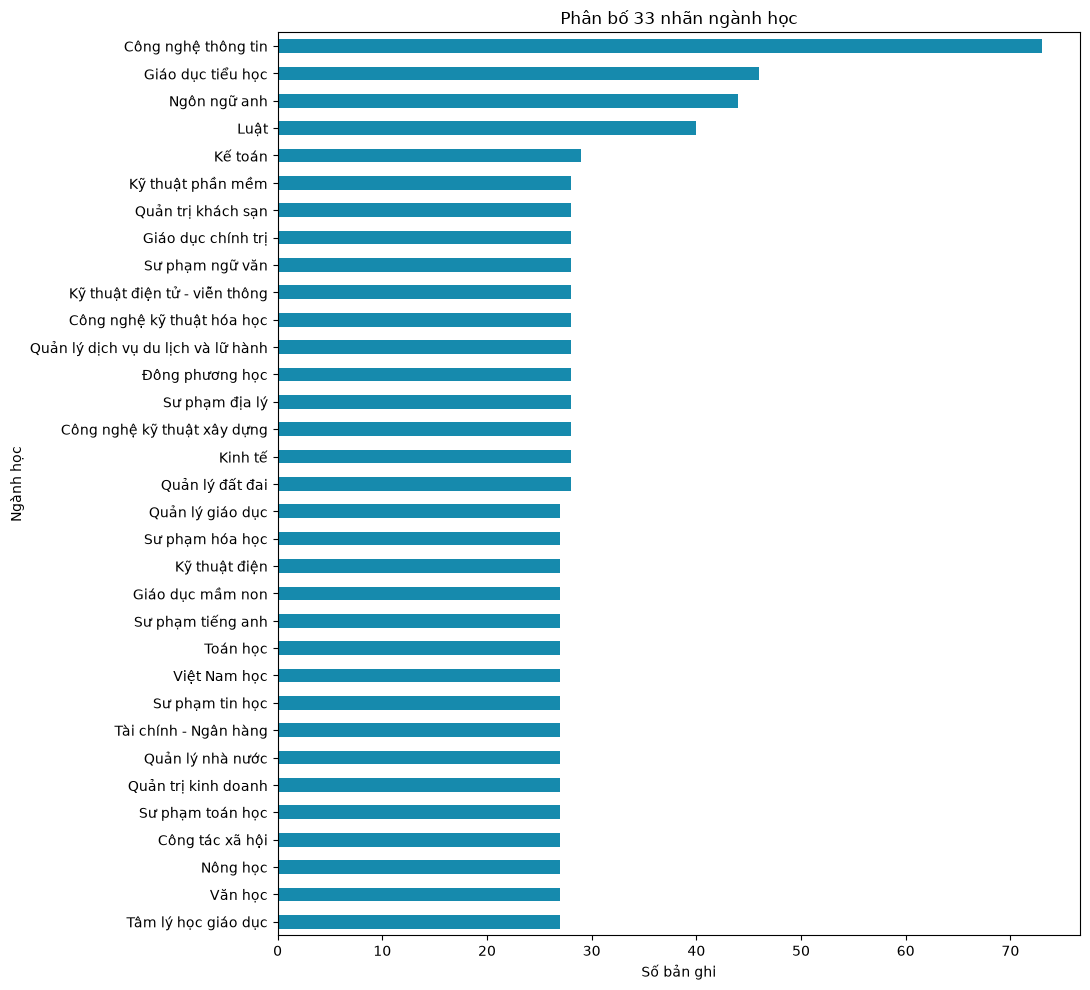

In [4]:
fig, ax = plt.subplots(figsize=(11, 10))
label_distribution.sort_values('Số bản ghi').plot.barh(
    x='Ngành học', y='Số bản ghi', ax=ax, legend=False, color='#168aad'
)
ax.set_title('Phân bố 33 nhãn ngành học')
ax.set_xlabel('Số bản ghi')
ax.set_ylabel('Ngành học')
fig.tight_layout()
plt.show()


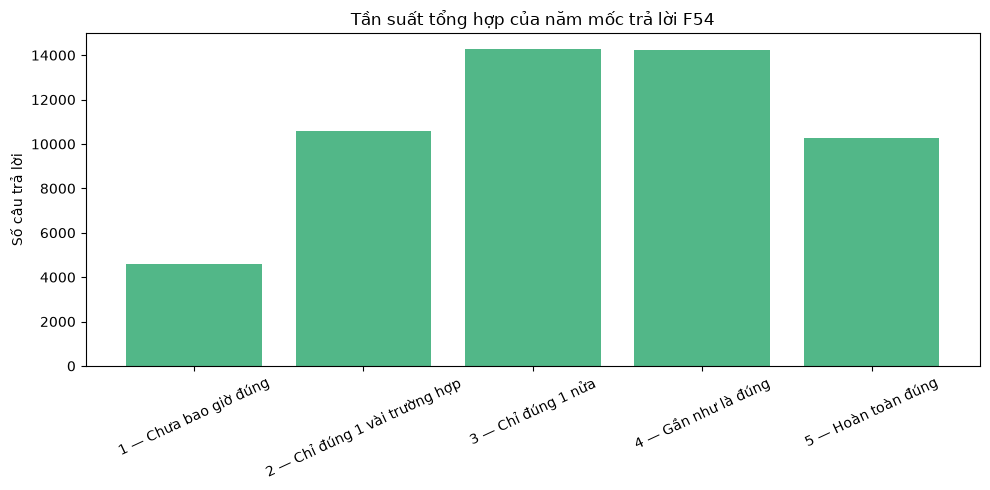

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(likert_distribution['Mốc F54'], likert_distribution['Số câu trả lời'], color='#52b788')
ax.set_title('Tần suất tổng hợp của năm mốc trả lời F54')
ax.set_ylabel('Số câu trả lời')
ax.tick_params(axis='x', labelrotation=25)
fig.tight_layout()
plt.show()


## 5. Đối chiếu bộ câu hỏi và tình trạng xác minh
F54 được đọc từ `src/models/f54Questionnaire.js`; Holland được đọc từ `src/models/hollandModel.js`. Việc gọi Node chỉ nạp hai module dữ liệu câu hỏi hiện có, không gọi website, database hay mạng.

F54 có 54 câu tự mô tả và thang trả lời mức độ đúng với bản thân. Source ghi rõ đây là raw feature, không gán chiều RIASEC và không đảo chiều câu hỏi. Không tìm thấy item-level codebook F54.

Holland hiện có 60 câu, theo thứ tự nhóm R, I, A, S, E, C; mỗi nhóm có 10 item và source gắn `type` cho từng item. Giao diện dùng thang mức độ yêu thích từ 1 đến 5. Tuy vậy, `public/js/evaluation.js` vẽ biểu đồ bằng các số cố định `[38, 44, 31, 40, 35, 28]`; đó là kết quả minh họa, không phải phép tính từ câu trả lời.

Hai thang đo dùng neo ngữ nghĩa khác nhau: F54 hỏi mức độ phát biểu đúng với người trả lời; Holland hỏi mức độ yêu thích hoạt động. Không có bằng chứng về crosswalk hợp lệ, chuyển 60 câu thành 54 câu, hay kiểm định F54 như một Holland scale. Không suy diễn ghép câu, chiều, trọng số hoặc đảo điểm.


In [6]:
questionnaire_comparison = pd.DataFrame([
    {
        'Bộ câu hỏi': 'F54',
        'Số câu': len(f54_items),
        'Nội dung': '54 phát biểu tự mô tả về đặc điểm và hoạt động.',
        'Thang đo': '1–5: ' + '; '.join(f"{item['value']}={item['label']}" for item in answer_scale),
        'Thứ tự': 'q1–q54; header workbook khớp nguyên văn với source.',
        'Mục tiêu đo lường': 'Đang được dùng như đầu vào truy hồi ngành đang học; chưa xác minh cấu trúc Holland.',
        'Codebook': 'Không thấy gán item vào R/I/A/S/E/C; source ghi raw feature, không reverse-code.',
        'Quy tắc chấm RIASEC': 'Chưa có codebook hoặc quy tắc chấm F54 được xác minh.',
        'Tình trạng xác minh': 'Header và 5 nhãn trả lời khớp cấu hình; giá trị đo lường chưa được kiểm định.',
    },
    {
        'Bộ câu hỏi': 'Holland trong repository',
        'Số câu': len(holland_items),
        'Nội dung': 'Các hoạt động/sở thích được nhóm theo sáu type R, I, A, S, E, C.',
        'Thang đo': '1=Rất không thích; 2=Không thích; 3=Phân vân / Không rõ; 4=Thích; 5=Rất thích.',
        'Thứ tự': 'R01–R10, I01–I10, A01–A10, S01–S10, E01–E10, C01–C10.',
        'Mục tiêu đo lường': 'Sở thích hoạt động theo nhóm Holland được ghi trong source.',
        'Codebook': 'Source có type cho từng item, 10 item mỗi nhóm; chưa phải bằng chứng kiểm định độc lập.',
        'Quy tắc chấm RIASEC': 'Giao diện hiện vẽ điểm demo cố định; không có quy tắc động từ đáp án được xác minh.',
        'Tình trạng xác minh': 'Đã kiểm tra cấu trúc item trong source; chưa xác minh psychometrics hoặc crosswalk.',
    },
])
display(questionnaire_comparison)

pd.set_option('display.max_rows', 120)
f54_inventory = pd.DataFrame([
    {'Thứ tự': item['question_order'], 'ID': item['question_id'], 'Nội dung': item['question_text']}
    for item in f54_items
])
holland_inventory = pd.DataFrame([
    {'Thứ tự': order, 'ID': item['id'], 'Type trong source': item['type'], 'Nội dung': item['text']}
    for order, item in enumerate(holland_items, start=1)
])
display(f54_inventory)
display(holland_inventory)


,Bộ câu hỏi,Số câu,Nội dung,Thang đo,Thứ tự,Mục tiêu đo lường,Codebook,Quy tắc chấm RIASEC,Tình trạng xác minh
0,F54,54,54 phát biểu tự mô tả về đặc điểm và hoạt động.,1–5: 1=Chưa bao giờ đúng; 2=Chỉ đúng 1 vài trư...,q1–q54; header workbook khớp nguyên văn với so...,Đang được dùng như đầu vào truy hồi ngành đang...,Không thấy gán item vào R/I/A/S/E/C; source gh...,Chưa có codebook hoặc quy tắc chấm F54 được xá...,Header và 5 nhãn trả lời khớp cấu hình; giá tr...
1,Holland trong repository,60,Các hoạt động/sở thích được nhóm theo sáu type...,1=Rất không thích; 2=Không thích; 3=Phân vân /...,"R01–R10, I01–I10, A01–A10, S01–S10, E01–E10, C...",Sở thích hoạt động theo nhóm Holland được ghi ...,"Source có type cho từng item, 10 item mỗi nhóm...",Giao diện hiện vẽ điểm demo cố định; không có ...,Đã kiểm tra cấu trúc item trong source; chưa x...


,Thứ tự,ID,Nội dung
0,1,q1,1. Tôi có tính tự lập
1,2,q2,2. Tôi suy nghĩ thực tế
2,3,q3,3. Tôi là người thích nghi với môi trường mới
3,4,q4,"4. Tôi có thể vận hành, điều khiển các máy móc..."
4,5,q5,5. Tôi làm các công việc thủ công như gấp giấy...
5,6,q6,6. Tôi thích tiếp xúc với thiên nhiên động vật...
6,7,q7,7. Tôi thích những công việc sử dụng tay chân ...
7,8,q8,8. Tôi thích những công việc thấy ngay kết quả
8,9,q9,9. Tôi thích những công việc ngoài trời hơn là...
9,10,q10,10. Tôi có tìm hiểu khám phá nhiều vấn đề mới


,Thứ tự,ID,Type trong source,Nội dung
0,1,R01,R,Tôi thích lắp ráp hoặc tháo các thiết bị để tì...
1,2,R02,R,"Tôi thích sửa chữa các máy móc, đồ điện hoặc t..."
2,3,R03,R,"Tôi thích sử dụng các dụng cụ như tua vít, kìm..."
3,4,R04,R,Tôi thích thực hiện các công việc đòi hỏi thao...
4,5,R05,R,"Tôi thích xây dựng mô hình, mạch điện hoặc các..."
5,6,R06,R,Tôi thích làm những công việc mà kết quả có th...
6,7,R07,R,Tôi thích làm việc với máy tính hoặc thiết bị ...
7,8,R08,R,Tôi thích thực hiện các nhiệm vụ thực hành hơn...
8,9,R09,R,Tôi thích các hoạt động ngoài trời có sử dụng ...
9,10,R10,R,Tôi thích tìm nguyên nhân và khắc phục một sự ...


## 7. Xác định bài toán ML
Bài toán có thể khảo sát từ nhãn hiện có là dự đoán đa lớp ngành học được ghi trong workbook. Đây chỉ là dự đoán nhãn ngành hiện có, không chứng minh mô hình nhận biết sở thích Holland hay ngành phù hợp thực sự.

Mục tiêu B — đề xuất ngành thực sự phù hợp với từng người — chưa có nhãn xác nhận tương ứng. Không tạo nhãn proxy hoặc suy ra nhãn B từ `Ngành học`.


In [7]:
ml_problem = pd.DataFrame([
    ['X', '54 câu trả lời F54 dạng nhãn văn bản; giữ nguyên, chưa mã hóa.'],
    ['y', 'Cột Ngành học; nhãn ngành đang học được ghi trong workbook.'],
    ['Số mẫu', len(df)],
    ['Số đặc trưng', len(question_columns)],
    ['Số lớp', len(class_counts)],
    ['Loại bài toán', 'Phân loại đa lớp có giám sát: dự đoán nhãn ngành hiện có.'],
    ['Giới hạn nhãn', 'Nhãn ngành không đo trực tiếp sở thích hay mức độ phù hợp nghề nghiệp.'],
    ['Mục tiêu B', 'Chưa có nhãn phù hợp được xác nhận; không được tự tạo.'],
], columns=['Thành phần', 'Định nghĩa hiện tại'])
display(ml_problem)


,Thành phần,Định nghĩa hiện tại
0,X,54 câu trả lời F54 dạng nhãn văn bản; giữ nguy...
1,y,Cột Ngành học; nhãn ngành đang học được ghi tr...
2,Số mẫu,1000
3,Số đặc trưng,54
4,Số lớp,33
5,Loại bài toán,Phân loại đa lớp có giám sát: dự đoán nhãn ngà...
6,Giới hạn nhãn,Nhãn ngành không đo trực tiếp sở thích hay mức...
7,Mục tiêu B,Chưa có nhãn phù hợp được xác nhận; không được...


## 8. Nhận xét và kết luận
Workbook có 1.000 dòng, 58 cột, gồm 54 câu trả lời và 33 nhãn ngành. Header câu hỏi đúng thứ tự 1–54 và khớp với F54 source. Năm nhãn trả lời khớp các neo F54; không có ô thiếu trong X/y hoặc câu trả lời ngoài neo. Có ô thiếu ở metadata. Không có dòng trùng hoàn toàn; hai dòng lặp vector trả lời, nên cần được xem xét sau khi xác định quy tắc xử lý, không tự xóa ở bước này. Phân bố lớp không đều: lớp nhiều nhất có 73 mẫu, ít nhất có 27 mẫu.

F54 và Holland 60 không thể coi là tương thích chỉ vì cùng đề cập đặc điểm cá nhân. Số câu, nội dung, thứ tự và ý nghĩa thang đo khác nhau; không có crosswalk được xác minh. F54 chưa có codebook RIASEC. Holland có type gắn trong source nhưng kết quả giao diện hiện là demo cố định, không phải scoring từ câu trả lời. Vì vậy không gọi model F54 là model Holland đã được kiểm định.

### Quyết định cần có trước công đoạn tiếp theo
1. Xác nhận chủ sở hữu và cách xử lý các trường metadata thiếu; không dùng metadata cá nhân làm đặc trưng.
2. Xác nhận ý nghĩa và nguồn gốc của nhãn `Ngành học`, cùng cách đánh giá phân loại ngành hiện có.
3. Nếu cần diễn giải Holland, yêu cầu codebook F54 có nguồn được duyệt: ánh xạ từng item, chiều chấm, đảo điểm, cách tổng hợp và bằng chứng kiểm định.
4. Nếu nghiên cứu mục tiêu ngành phù hợp thực sự, cần nhãn riêng được xác nhận; không dùng ngành đang học làm nhãn thay thế.
5. Quyết định cách đánh giá hai mẫu có vector trả lời lặp sau khi xem xét provenance; notebook này không loại hoặc gộp chúng.

Dừng tại KDD 00. Chưa làm sạch, chuẩn hóa, chia train/test, chọn đặc trưng hoặc huấn luyện; chưa tạo notebook tiếp theo.
